# 📘 Notebook 4: Deep Learning Architectures
**MATH 6388 — Statistical and Machine Learning**  
**Instructor: Farhad Pourkamali**  

# Part 1: Convolutional Neural Networks

The goal is to capture **spatial features** from images, focusing on pixel arrangements and their relationships

* Main Types of Layers:

    * Convolutional Layer: Extracts features using filters
    * Pooling Layer: Reduces the dimensionality and highlights dominant features
    * Fully-connected (FC) or Dense Layer: Combines features for final classification or regression
    
* Advantages over Multilayer Perceptrons (MLPs):

    * Fewer parameters to learn due to shared weights in filters
    * Translation invariance: Treats all patches of the image uniformly, regardless of their position
    * Locality: Uses only small neighborhoods of pixels to compute hidden representations, making it computationally efficient
    
* Example: The input is a two-dimensional tensor with a height of 3 and width of 3. The filter or kernel has a height of 2 and width of 2 (credit: Dive into Deep Learning, https://d2l.ai/)

<img src="https://d2l.ai/_images/correlation.svg">


* A convolutional filter slides across an image, multiplying corresponding entries in each local patch and summing the results.
* Consider a simple $3\times 3$ image:

$$
\text{image}=
\begin{bmatrix}
    a_{11} & a_{12} & a_{13} \\
    a_{21} & a_{22} & a_{23} \\
    a_{31} & a_{32} & a_{33}
\end{bmatrix}.
$$

* Consider a $2\times 2$ filter:

$$
\text{filter}=
\begin{bmatrix}
    f_{11} & f_{12} \\
    f_{21} & f_{22}
\end{bmatrix}.
$$

* With stride $1$, no padding, and no bias, the output is a $2\times 2$ feature map:

$$
\text{output}=
\begin{bmatrix}
a_{11}f_{11}+a_{12}f_{12}+a_{21}f_{21}+a_{22}f_{22}
&
a_{12}f_{11}+a_{13}f_{12}+a_{22}f_{21}+a_{23}f_{22}
\\[6pt]
a_{21}f_{11}+a_{22}f_{12}+a_{31}f_{21}+a_{32}f_{22}
&
a_{22}f_{11}+a_{23}f_{12}+a_{32}f_{21}+a_{33}f_{22}
\end{bmatrix}.
$$

**Note:** Technically, this operation is cross-correlation, which PyTorch and other deep-learning libraries conventionally call convolution.

* If the image size is $n_h\times n_w$ and the size of the convolution filter is $k_h\times k_w$, we get

$$\big(n_h - k_h + 1 \big)\times \big(n_w - k_w + 1 \big)$$

* Thus, the output size is slightly smaller than the input size

* "Padding" refers to the technique of adding extra rows and columns of zeros around the input data before applying a convolution operation
    * control the spatial dimensions of the output feature maps
    * preserve information at the edges of the input
    
* If we add a total of $p_h$ rows of padding and $p_w$ columns of padding, the output shape will be

$$\big(n_h - k_h + p_h + 1 \big)\times \big(n_w - k_w + p_w + 1 \big)$$

* Hence, we can give the input and output the same height and width by choosing

$$p_h = k_h - 1, \; p_w = k_w - 1$$

* This is why CNNs commonly use convolution filters with odd height and width values
    * padding with the same number of rows on top and bottom, and the same number of columns on left and right
    
* "Stride" controls how much the filter shifts (horizontally and vertically) between successive applications to generate the output feature map
    * That is, the number of rows and columns traversed per slide
    * A stride of 1 means that the filter moves one pixel at a time (no skipping)
    * A stride greater than 1 causes the filter to skip pixels
    
$$\lfloor\big(n_h-k_h+p_h+s_h\big)/s_h\rfloor \times \lfloor\big(n_w-k_w+p_w+s_w\big)/s_w\rfloor$$

* Example: strides of 3 and 2 for height and width (credit: Dive into Deep Learning, https://d2l.ai/)

<img src=https://d2l.ai/_images/conv-stride.svg>

* In a convolution layer, you typically have multiple filters. Each filter is a small, learnable tensor that slides or convolves over the input data

* The number of filters you specify in a layer determines the number of output channels

* Denote by $C_i$ and $C_o$ the number of input and output channels

    * Let $k_h$ and $k_w$ be the height and width of the filter
    * To get an output with multiple channels, we can create a filter tensor of shape $k_h\times k_w \times C_i$ for every output channel
    * Hence, we concatenate them on the output channel dimension, so that the shape of the convolution filter is $k_h\times k_w \times C_i \times C_o$


* Example (credit: Dive into Deep Learning, https://d2l.ai/)

<img src="https://d2l.ai/_images/conv-multi-in.svg">

* The primary purpose of max pooling is to downsample the spatial dimensions of feature maps

* This reduction in spatial resolution helps control the computational complexity of the network

* Max pooling introduces a degree of position invariance, meaning that the model can recognize features regardless of their precise location in the input

* In each pooling window (typically 2x2 or 3x3), max pooling selects the maximum value

    * It operates on each channel (feature map) of the input independently

* Example (credit: Dive into Deep Learning, https://d2l.ai/)


<img src="https://d2l.ai/_images/pooling.svg">

Let's load two sample images and convert them to a float tensor:

In [1]:
import numpy as np
import torch
from sklearn.datasets import load_sample_images
# https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_sample_images.html

sample_images = np.stack(load_sample_images()["images"])

sample_images = torch.tensor(sample_images, dtype=torch.float32) / 255

In [2]:
sample_images.shape # [batch, height, width, channels]

torch.Size([2, 427, 640, 3])

In [3]:
# PyTorch expects [batch_size, channels, height, width]

sample_images_permuted = sample_images.permute(0, 3, 1, 2)

sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

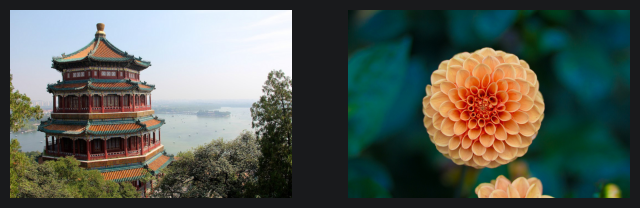

In [6]:
import matplotlib.pyplot as plt

def plot_image(image):
    plt.imshow(image.permute(1, 2, 0))
    plt.axis("off")

plt.figure(figsize=(8, 4))
for index, image in enumerate(sample_images_permuted):
    plt.subplot(1, 2, index + 1)
    plot_image(image)

This code crops the center of each image to a height of 70 pixels and a width of 120 pixels, preserving the batch and channel dimensions, and then displays the resulting tensor shape.

In [7]:
import torchvision
import torchvision.transforms.v2 as T

cropped_images = T.CenterCrop((70, 120))(sample_images_permuted)
cropped_images.shape

torch.Size([2, 3, 70, 120])

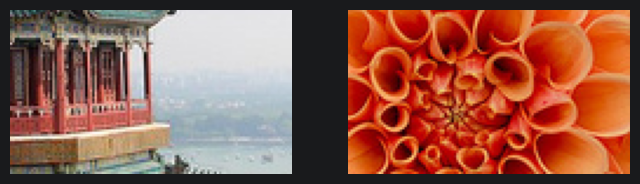

In [8]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plot_image(cropped_images[0])
plt.subplot(1, 2, 2)
plot_image(cropped_images[1])

We now apply a convolutional layer to our cropped RGB images.

- `in_channels=3`: each input image has three color channels.
- `out_channels=32`: the layer learns 32 filters, producing 32 feature maps per image.
- `kernel_size=7`: each filter covers a $7\times7$ spatial region and spans all three input channels. Thus, each filter contains $3\times7\times7$ weights, plus one bias.

At each position, a filter multiplies its weights by the corresponding image values, sums the products across all three channels, and adds its bias.

By default, the stride is 1 and there is no padding. Therefore, a $70\times120$ input produces feature maps of size

$$
H_{\text{out}}=70-7+1=64,
\qquad
W_{\text{out}}=120-7+1=114.
$$

The filters are randomly initialized and have not yet been trained.

In [9]:
import torch.nn as nn

torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7)
fmaps = conv_layer(cropped_images)

fmaps.shape

torch.Size([2, 32, 64, 114])

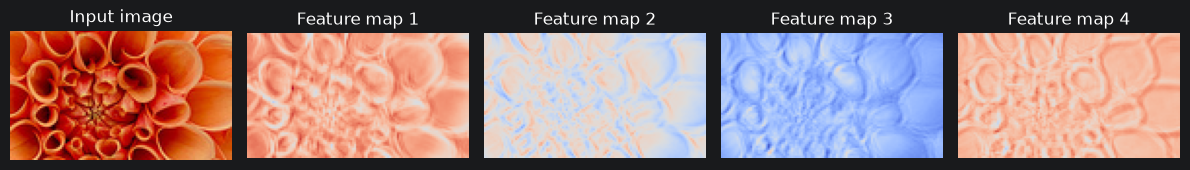

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(12, 4))

axes[0].imshow(cropped_images[1].detach().cpu().permute(1, 2, 0))
axes[0].set_title("Input image")

# Use a shared color scale to compare responses across filters.
maps = fmaps[1, :4].detach().cpu()
limit = maps.abs().max().item()

for k in range(4):
    axes[k + 1].imshow(
        maps[k], cmap="coolwarm", vmin=-limit, vmax=limit
    )
    axes[k + 1].set_title(f"Feature map {k + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

As you can see, different randomly initialized filters produce different responses to the same image. Some may highlight edges or changes in intensity, but they have not yet learned which patterns are useful for our task. During training, the filter weights are updated to help the network make better predictions. Early layers often learn simple patterns, such as edges and textures, while deeper layers combine these into more complex features.

Max pooling reduces the spatial dimensions of a feature map by keeping the largest value in each local window.

In [11]:
import torch
import torch.nn as nn

# A single image with one channel: [batch, channels, height, width]
image = torch.tensor([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 8, 1],
    [3, 4, 2, 9]
], dtype=torch.float32).unsqueeze(0).unsqueeze(0)

max_pool = nn.MaxPool2d(kernel_size=2)
pooled_image = max_pool(image)

print("Input:")
print(image[0, 0])

print("\nAfter max pooling:")
print(pooled_image[0, 0])

print("\nInput shape:", image.shape)
print("Output shape:", pooled_image.shape)

Input:
tensor([[1., 3., 2., 4.],
        [5., 6., 1., 2.],
        [7., 2., 8., 1.],
        [3., 4., 2., 9.]])

After max pooling:
tensor([[6., 4.],
        [7., 9.]])

Input shape: torch.Size([1, 1, 4, 4])
Output shape: torch.Size([1, 1, 2, 2])


## CNN Architecture

For this example, we will use the CIFAR10 dataset. It has the classes: ‘airplane’, ‘automobile’, ‘bird’, ‘cat’, ‘deer’, ‘dog’, ‘frog’, ‘horse’, ‘ship’, ‘truck’. The images in CIFAR-10 are of size 3x32x32, i.e. 3-channel color images of 32x32 pixels in size.


<center>
<img src="https://docs.pytorch.org/tutorials/_images/cifar10.png"
         height="400">
<center>

<center>
<img src="https://github.com/farhad-pourkamali/MATH6388Updated/blob/main/Images/cnn_arch.png?raw=true"
         height="200">
<center>

In [12]:
# Load and normalize CIFAR10

import torch
import torchvision
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 32

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')



22.8%


KeyboardInterrupt: 

In [ ]:
# Define the model
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

In [ ]:
# Define a Loss function and optimizer

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [ ]:
# Train the network
for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 200 == 199:    # print every 200 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 200:.3f}')
            running_loss = 0.0



print('Finished Training')

In [ ]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

In [ ]:
# Test the network on the test data

dataiter = iter(testloader)
images, labels = next(dataiter)

In [ ]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

outputs = net(images)

# Helper to un-normalize and show images for testing
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# print images
imshow(torchvision.utils.make_grid(images[:4]))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))


_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

In [ ]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

# Part 2: Pretrained Models and Transfer Learning

Building and training a model from scratch takes a massive amount of data, time, and computing power. **Transfer Learning** allows us to take a model that has already been trained on a giant dataset (like ImageNet, which has over 1 million images and 1,000 classes) and adapt it to our specific task (like CIFAR-10).

**Why it works:** The early layers of a vision model learn to recognize fundamental shapes, edges, and textures, which are universally useful. We simply "freeze" those learned features and only train a new final layer to recognize our specific 10 classes.

**Where to find them:**
* **`torchvision.models`**: Built directly into PyTorch (ResNet, VGG, MobileNet, EfficientNet, etc.).
Link: https://pytorch.org/hub/?_sft_lf-model-type=vision

In [ ]:
torchvision.models.list_models()

In [ ]:
import torch
import torchvision
from torchvision.transforms import v2

# ImageNet standard normalization and resizing
transform = v2.Compose([
    v2.Resize((224, 224)), # Resize CIFAR10 images to fit the pretrained model
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

batch_size = 32

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


<center>
<img src="https://d2l.ai/_images/resnet18-90.svg"
         height="200">
<center>

In a regular block (left), the portion within the dotted-line box must directly learn the mapping $f(\mathbf{x})$
. In a residual block (right), the portion within the dotted-line box needs to learn the residual mapping $g(\mathbf{x})=f(\mathbf{x})-\mathbf{x}$.


<center>

<img src="https://d2l.ai/_images/residual-block.svg"
         height="250">

<center>

In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights

# 1. Load the pre-trained ResNet18 model
weights = ResNet18_Weights.DEFAULT
net = resnet18(weights=weights)

# 2. Freeze the base layers so we don't destroy the pre-trained features
for param in net.parameters():
    param.requires_grad = False

# 3. Replace the final fully connected layer (fc) to output 10 classes instead of 1000
# By default, new layers have requires_grad=True
num_ftrs = net.fc.in_features
net.fc = nn.Linear(num_ftrs, 10)

# Move model to GPU if available (Pretrained models are larger, GPU helps!)
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
net = net.to(device)

# Define loss and optimizer (only optimizing the new fc layer)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.fc.parameters(), lr=0.001)

In [ ]:
print(f'Training on {device}...')

for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data[0].to(device), data[1].to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 200 == 199:    # print every 200 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 200:.3f}')
            running_loss = 0.0

print('Finished Training')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Save
PATH = './cifar_transfer_net.pt'
torch.save(net.state_dict(), PATH)

# Helper to un-normalize and show images for testing
def imshow(img):
    img = img * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1) + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Get a batch of test data
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images[:4]))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

# Load the model back up (just to prove it works)
net.load_state_dict(torch.load(PATH, weights_only=True))
net.eval() # Set to evaluation mode

# Predict
images = images.to(device)
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted:   ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

In [ ]:
correct = 0
total = 0

# Set network to evaluation mode and disable gradient calculation
net.eval()
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)

        # calculate outputs by running images through the network
        outputs = net(images)

        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the pretrained network on the 10000 test images: {100 * correct // total} %')

## Predictive Entropy: Finding Images Worth Inspecting

For an input image $\mathbf{x}_i$, our trained classifier produces a probability for each of the $K$ possible classes:

$$
p_\theta(k \mid \mathbf{x}_i)
=
\mathbb{P}_\theta(Y=k \mid \mathbf{x}_i),
\qquad k=1,\ldots,K.
$$

Here, $\theta$ denotes the model parameters, and $p_\theta(k \mid \mathbf{x}_i)$ is the model's estimated probability that image $\mathbf{x}_i$ belongs to class $k$. These probabilities are obtained by applying **softmax** to the model's output logits, and they satisfy

$$
p_\theta(k \mid \mathbf{x}_i)\ge 0,
\qquad
\sum_{k=1}^{K}p_\theta(k \mid \mathbf{x}_i)=1.
$$

### What is entropy?

**Entropy measures how spread out a probability distribution is.** For image $\mathbf{x}_i$, its predictive entropy is

$$
\boxed{
H_i
=
-\sum_{k=1}^{K}
p_\theta(k \mid \mathbf{x}_i)
\log p_\theta(k \mid \mathbf{x}_i)
}
$$

We use the natural logarithm and the convention $0\log 0=0$. The entropy satisfies

$$
0\le H_i\le \log K.
$$

- **Low entropy:** most probability is concentrated on one class; the model is confident.
- **High entropy:** probability is spread across several classes; the model is uncertain.
- **Maximum entropy:** all classes receive probability $1/K$, giving $H_i=\log K$.


### Using entropy to inspect our classifier

After adapting ResNet18 to our classification task, we can use predictive entropy to identify images worth examining:

1. Compute the predicted class probabilities for each evaluation image.
2. Calculate its entropy $H_i$.
3. Sort the images from highest to lowest entropy.
4. Display the highest-entropy images alongside their predicted probabilities and, when available, their true labels.

These images may reveal ambiguous objects, blur, occlusion, unusual appearances, or examples outside the training classes.

> **Important:** High entropy indicates model uncertainty, not necessarily an outlier. A familiar image can be ambiguous, and an unfamiliar image can receive a confidently wrong prediction.


### Exercise

The previous cell computes the test accuracy of our adapted network. Now extend this evaluation to investigate **which images the model is most uncertain about**.

Write code to complete the following tasks:

1. **Compute predictive entropy for every test image.**
   - Use `net.eval()` and `torch.no_grad()`, as in the previous cell.
   - Apply softmax to the output logits to obtain class probabilities.
   - For each image $\mathbf{x}_i$, calculate
     $$
     H_i=-\sum_{k=1}^{K}
     p_\theta(k\mid\mathbf{x}_i)\log p_\theta(k\mid\mathbf{x}_i).
     $$
   - Store the entropy, image, predicted label, and true label together so they remain correctly matched.
   - Ensure your computation handles probabilities near zero without producing numerical errors.

2. **Plot the distribution of predictive entropies.**
   - Create a histogram using the entropy values from all test images.
   - Label the horizontal axis **Predictive entropy** and the vertical axis **Number of images**.
   - Recall that entropy ranges from $0$ to $\log K$, where $K$ is the number of classes.

3. **Visualize the 20 images with the highest entropy.**
   - Sort the images by entropy in descending order.
   - Display the top 20 in a **4 × 5 grid**, starting with the highest-entropy image.
   - Above each image, show its entropy, predicted class, and true class.
   - If your preprocessing normalized the images, undo that normalization before displaying them.

**Discussion:** Are the highest-entropy predictions mostly incorrect, or are some correct? What visual characteristics might explain the model's uncertainty? Does high entropy necessarily mean that an image is an outlier?

# Part 3: Recurrent Neural Networks

* A key characteristic of all the neural networks we have explored so far, such as densely connected networks and convolutional networks, is that they lack memory.

    * Each input presented to these networks is processed independently, with no *state* retained between samples.


* This lack of memory means they cannot leverage information from previous inputs, making them unsuitable for tasks that require understanding context over time, such as time-series or sequential data.

* A recurrent neural network (RNN) processes sequences by iterating through elements and maintaining a state that retains information about what it has seen so far.
    * Essentially, an RNN is a type of neural network with an internal loop, allowing it to handle sequential data effectively.
    
    <img src="https://github.com/farhad-pourkamali/MATH6388Online/blob/main/images/RNN1.png?raw=true" width=500>
    
* To clarify the concepts of loop and state, let us consider the forward pass of a simple RNN. This RNN takes as input a rank-2 tensor of size ```(num_timesteps, num_features)```. It loops over timesteps, and at each timestep, it considers its current state at ```t``` and the input at ```t``` (of shape ```(num_features,)```), combining them to obtain the output at ```t```.

*  Each "unrolled" layer represents the RNN's computations at a particular timestep, showing how the hidden state and output are updated at each step.
    * The hidden state from the previous timestep is fed into the next timestep along with the new input.

    $$\mathbf{h}_t=f(\mathbf{x}_t, \mathbf{h}_{t-1}),\;\;y_t=g(\mathbf{h}_t)$$


<img src="https://github.com/farhad-pourkamali/MATH6388Online/blob/main/images/time.png?raw=true" width=350>

Starting from an initial state, typically $\mathbf{h}_0=\mathbf{0}$, the network processes the sequence as follows:

$$
\begin{aligned}
\mathbf{h}_1
&= \tanh(W_x\mathbf{x}_1 + W_h\mathbf{h}_0 + \mathbf{b}),\\
\mathbf{h}_2
&= \tanh(W_x\mathbf{x}_2 + W_h\mathbf{h}_1 + \mathbf{b}),\\
\mathbf{h}_3
&= \tanh(W_x\mathbf{x}_3 + W_h\mathbf{h}_2 + \mathbf{b}).
\end{aligned}
$$

Although each update directly uses only the current input and previous state, the previous state depends on earlier inputs. Thus, $\mathbf{h}_3$ can contain information from $\mathbf{x}_1$, $\mathbf{x}_2$, and $\mathbf{x}_3$.

**The same matrices $W_x$ and $W_h$ and bias $\mathbf{b}$ are reused at every time step.** Unrolling an RNN does not create a separate set of parameters for each position in the sequence.



### Beyond the vanilla RNN: LSTM and GRU

A vanilla RNN updates its hidden state using

$$
\mathbf{h}_t
=
\tanh\!\left(
W_x\mathbf{x}_t+W_h\mathbf{h}_{t-1}+\mathbf{b}
\right).
$$

This gives the network a way to carry information through time. However, the same transformation repeatedly mixes the previous state with new inputs. Information from much earlier observations can become difficult to preserve and learn from.

**LSTM** and **GRU** networks address this difficulty using **learned gates**: vectors that control how information is retained, discarded, and updated.



### What is a gate?

A gate is a vector computed using a sigmoid function:

$$
\mathbf{g}_t
=
\sigma(W_g\mathbf{x}_t+U_g\mathbf{h}_{t-1}+\mathbf{b}_g),
\qquad
\sigma(a)=\frac{1}{1+e^{-a}}.
$$

Every component of $\mathbf{g}_t$ lies between zero and one. The gate controls information through elementwise multiplication, denoted by $\odot$.

For example,

$$
\begin{bmatrix}
0.99\\
0.01\\
0.50
\end{bmatrix}
\odot
\begin{bmatrix}
2\\
-3\\
4
\end{bmatrix}
=
\begin{bmatrix}
1.98\\
-0.03\\
2
\end{bmatrix}.
$$

The first component is mostly retained, the second is mostly suppressed, and the third is partially retained.

**Gates are learned and input-dependent.** Their values change with the current input and previous hidden state. They are not fixed settings chosen by the user.

### Long short-term memory: two states and three gates

An LSTM maintains two state vectors:

- A **cell state**, $\mathbf{c}_t\in\mathbb{R}^{m}$, that carries information along an additive memory path.
- A **hidden state**, $\mathbf{h}_t\in\mathbb{R}^{m}$, that provides a gated representation of the cell state.

Both states evolve at every time step. Three gates determine how they change.

<img src="https://media.datacamp.com/legacy/image/upload/v1647442110/image3_nsnxp3.png" height=300>

#### Step A: Decide what to retain from the previous cell state

The **forget gate** is

$$
\mathbf{f}_t
=
\sigma(W_f\mathbf{x}_t+U_f\mathbf{h}_{t-1}+\mathbf{b}_f).
$$

The product

$$
\mathbf{f}_t\odot\mathbf{c}_{t-1}
$$

selects how much of each previous cell-state component to retain.

A value near one preserves that component; a value near zero largely discards it.

#### Step B: Decide what new information to write

The **input gate** is

$$
\mathbf{i}_t
=
\sigma(W_i\mathbf{x}_t+U_i\mathbf{h}_{t-1}+\mathbf{b}_i).
$$

The network also constructs candidate cell content:

$$
\widetilde{\mathbf{c}}_t
=
\tanh(W_c\mathbf{x}_t+U_c\mathbf{h}_{t-1}+\mathbf{b}_c).
$$

These vectors serve different purposes:

- $\widetilde{\mathbf{c}}_t$ proposes **what information could be added**.
- $\mathbf{i}_t$ determines **how much of it to add**.

#### Step C: Update the cell state

The new cell state combines retained information with selected new information:

$$
\boxed{
\mathbf{c}_t
=
\underbrace{
\mathbf{f}_t\odot\mathbf{c}_{t-1}
}_{\text{retained memory}}
+
\underbrace{
\mathbf{i}_t\odot\widetilde{\mathbf{c}}_t
}_{\text{new information}}
}
$$

For a particular component, if the forget gate is near one and the input gate is near zero, then

$$
c_{t,j}\approx c_{t-1,j}.
$$

The network can therefore carry that information forward with little change.

#### Step D: Decide what to expose through the hidden state

The **output gate** is

$$
\mathbf{o}_t
=
\sigma(W_o\mathbf{x}_t+U_o\mathbf{h}_{t-1}+\mathbf{b}_o).
$$

The hidden state becomes

$$
\boxed{
\mathbf{h}_t
=
\mathbf{o}_t\odot\tanh(\mathbf{c}_t).
}
$$

The output gate controls which components of the transformed cell state are exposed through the hidden state. It does not directly produce our final predicted price; a separate linear layer performs that task.


### Gated recurrent unit: a simpler gated state

A GRU uses a single hidden state $\mathbf{h}_t$ and does not maintain a separate cell state. It uses two gates:

- A **reset gate**, which controls how the previous hidden state contributes to candidate information.
- An **update gate**, which controls the balance between the previous hidden state and the candidate.

<img src="https://media.datacamp.com/legacy/image/upload/v1647442111/image10_zgefie.png" height=300>

#### Step A: Compute the reset gate

$$
\mathbf{r}_t
=
\sigma(
W_r\mathbf{x}_t+\mathbf{b}_{xr}
+
U_r\mathbf{h}_{t-1}+\mathbf{b}_{hr}
).
$$

A reset-gate component near zero suppresses the corresponding transformed past-state contribution when forming the candidate.

This does **not** directly erase the stored hidden state. It affects the candidate computation.

#### Step B: Construct a candidate hidden state

$$
\widetilde{\mathbf{h}}_t
=
\tanh\!\left(
W_n\mathbf{x}_t+\mathbf{b}_{xn}
+
\mathbf{r}_t\odot
\left(U_n\mathbf{h}_{t-1}+\mathbf{b}_{hn}\right)
\right).
$$

The candidate combines the current input with a gated contribution from the previous hidden state.

#### Step C: Compute the update gate

$$
\mathbf{z}_t
=
\sigma(
W_z\mathbf{x}_t+\mathbf{b}_{xz}
+
U_z\mathbf{h}_{t-1}+\mathbf{b}_{hz}
).
$$

#### Step D: Blend the previous state with the candidate

$$
\boxed{
\mathbf{h}_t
=
\underbrace{
\mathbf{z}_t\odot\mathbf{h}_{t-1}
}_{\text{retained state}}
+
\underbrace{
(\mathbf{1}-\mathbf{z}_t)\odot\widetilde{\mathbf{h}}_t
}_{\text{candidate contribution}}
}
$$


PyTorch implements all gate computations inside `nn.LSTM` and `nn.GRU`; we do not need to program them individually. Which architecture forecasts better must be determined empirically, including comparison with the persistence baseline.

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error


def set_seed(seed=455):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)

Device: mps


The dataset contains daily Mastercard stock information, including opening, closing, high, and low prices and trading volume.

We load the CSV file and use the date as its index.

Our prediction target is the daily high price, which is the highest price reached during a trading day. This example uses only that variable; the other columns are not inputs to the models.

Inspecting the first few rows, summary statistics, and missing-value counts helps us check the data before modeling.

Sorting by date is essential because the order of observations determines the sequences presented to the recurrent networks.

In [ ]:
DATA_PATH = "Mastercard_stock_history.csv"

dataset = pd.read_csv(
    DATA_PATH,
    index_col="Date",
    parse_dates=["Date"],
).sort_index()

dataset = dataset.drop(
    columns=["Dividends", "Stock Splits"],
    errors="ignore",
)

display(dataset.head())
display(dataset.describe())

print("Missing values:")
print(dataset.isna().sum())

,Open,High,Low,Close,Volume
Date,,,,,
2006-05-25 00:00:00-04:00,3.677800,4.202548,3.668674,4.197985,395343000
2006-05-26 00:00:00-04:00,4.225363,4.265517,4.025502,4.100336,103044000
2006-05-30 00:00:00-04:00,4.103990,4.104902,3.910517,4.015467,49898000
2006-05-31 00:00:00-04:00,4.047406,4.139579,4.047406,4.101250,30002000
2006-06-01 00:00:00-04:00,4.100334,4.389630,4.097596,4.335786,62344000


,Open,High,Low,Close,Volume
count,4733.000000,4733.000000,4733.000000,4733.000000,4.733000e+03
mean,157.218445,158.751430,155.650434,157.248719,1.062101e+07
std,151.827873,153.182400,150.433224,151.846666,1.632991e+07
min,3.677800,4.024589,3.668674,4.006337,6.411000e+05
25%,24.703870,25.007020,24.386382,24.721483,3.020000e+06
50%,87.602214,88.402167,86.976627,87.724739,4.742400e+06
75%,298.458871,302.054722,294.400031,298.368073,1.062100e+07
max,577.330017,582.229980,570.000000,576.309998,3.953430e+08


Missing values:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


We train the models using observations from 2016 through 2020 and evaluate them using observations from 2021 onward.
For forecasting, the training data must precede the test data.

A random split of individual observations could allow information from the future to influence predictions about the past.

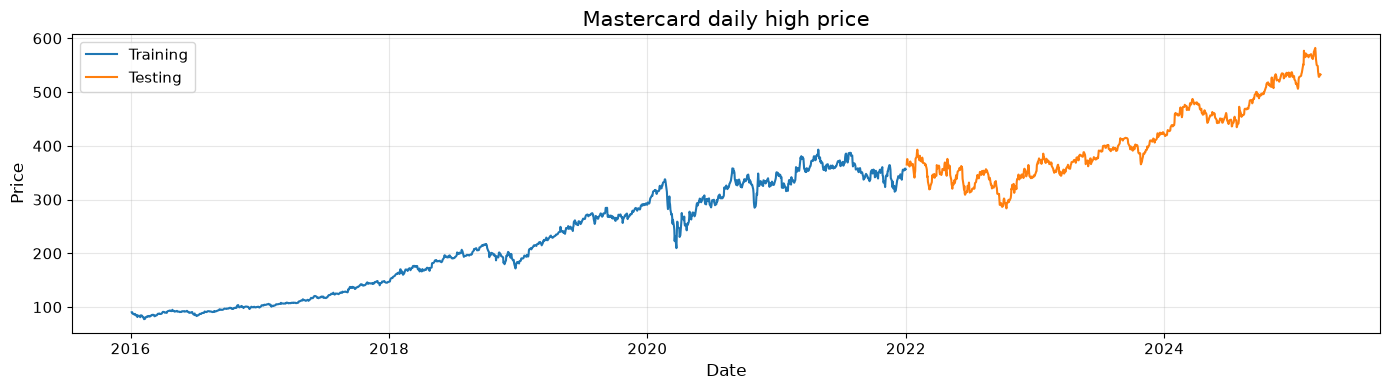

In [ ]:
import matplotlib.dates as mdates

# Ensure the index contains dates rather than text labels.
dataset.index = pd.to_datetime(dataset.index, utc=True).tz_convert(None) # "2016-01-04"  →  Timestamp("2016-01-04 00:00:00")
dataset = dataset.sort_index()

train_start = "2016-01-01"
train_end = "2021-12-31"
test_start = "2022-01-01"

prices = dataset["High"].astype(float)

train_prices = prices.loc[train_start:train_end]
test_prices = prices.loc[test_start:]

if len(train_prices) <= 60 or len(test_prices) == 0:
    raise ValueError("The dataset does not contain enough data for these dates.")

if train_prices.isna().any() or test_prices.isna().any():
    raise ValueError("Handle missing High prices before creating sequences.")

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(train_prices.index, train_prices, label="Training", linewidth=1.5)
ax.plot(test_prices.index, test_prices, label="Testing", linewidth=1.5)

# Limit the number of date labels to prevent overlap.
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.minorticks_off()

ax.set_title("Mastercard daily high price", fontsize=15)
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Price", fontsize=12)
ax.tick_params(axis="both", labelsize=11)

ax.legend(fontsize=11)
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

We use min–max scaling to map the training prices into the interval $[0,1]$:

$$
\widetilde{x}_t =
\frac{x_t-x_{\min,\mathrm{train}}}
{x_{\max,\mathrm{train}}-x_{\min,\mathrm{train}}}
$$

The function `make_sequences` converts the time series into supervised learning examples. With `window_size = 60`, each input contains **60 consecutive trading-day prices**, and its target is the price on the next trading day:

$$
\underbrace{
(\widetilde{x}_{t-60},\ldots,\widetilde{x}_{t-1})
}_{\text{input sequence}}
\quad\longrightarrow\quad
\underbrace{\widetilde{x}_t}_{\text{target}}.
$$

The window advances by one observation for each new example, so neighboring windows overlap.

For a smaller window of three observations, the process would look like this:

| Input sequence | Target |
|---|---|
| $(\widetilde{x}_1,\widetilde{x}_2,\widetilde{x}_3)$ | $\widetilde{x}_4$ |
| $(\widetilde{x}_2,\widetilde{x}_3,\widetilde{x}_4)$ | $\widetilde{x}_5$ |
| $(\widetilde{x}_3,\widetilde{x}_4,\widetilde{x}_5)$ | $\widetilde{x}_6$ |


In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(
    train_prices.to_numpy().reshape(-1, 1)
).astype(np.float32)

test_scaled = scaler.transform(
    test_prices.to_numpy().reshape(-1, 1)
).astype(np.float32)


def make_sequences(values, window_size):
    X, y = [], []

    for target_index in range(window_size, len(values)):
        X.append(values[target_index - window_size:target_index])
        y.append(values[target_index])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
    )


window_size = 60

X_train, y_train = make_sequences(train_scaled, window_size)

# Include the final 60 training observations so that we can
# predict the very first test observation.
test_context = np.concatenate(
    [train_scaled[-window_size:], test_scaled],
    axis=0,
)

X_test, y_test = make_sequences(test_context, window_size)

print("X_train:", X_train.shape)  # (training samples, 60, 1)
print("y_train:", y_train.shape)  # (training samples, 1)
print("X_test: ", X_test.shape)   # (test samples, 60, 1)
print("y_test: ", y_test.shape)   # (test samples, 1)

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train),
)

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test),
)


def make_train_loader(batch_size=32):
    generator = torch.Generator().manual_seed(455)

    return DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
    )


test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
)

X_train: (1451, 60, 1)
y_train: (1451, 1)
X_test:  (804, 60, 1)
y_test:  (804, 1)


### Define a recurrent neural network for next-day prediction

The `RecurrentRegressor` class defines a model that takes a sequence of 60 daily high prices and predicts the next trading day's high price. We can choose either an **LSTM** or a **GRU** as its recurrent layer.

This is a **many-to-one regression problem**: many input observations produce one continuous-valued prediction.

#### 1. Define the model and choose the recurrent layer

The class inherits from `nn.Module`, the base class for PyTorch neural networks. Calling `super().__init__()` initializes the functionality PyTorch needs to track the model's layers and trainable parameters.

The `cell_type` argument selects the recurrent architecture:

- `"LSTM"` creates a long short-term memory layer.
- `"GRU"` creates a gated recurrent unit layer.

Both architectures process observations sequentially and update an internal representation of the sequence. Their learned gates control which information to retain, update, or discard. An LSTM maintains both a **hidden state** and a **cell state**, whereas a GRU maintains a hidden state without a separate cell state.

The rest of our model works with either architecture.

#### 2. Interpret the recurrent-layer settings

The recurrent layer is configured using four arguments:

| Argument | Value | Meaning |
|---|---|---|
| `input_size` | `1` | Each time step contains one feature: the scaled daily high price. |
| `hidden_size` | `125` | The hidden state contains 125 learned features. |
| `num_layers` | `1` | The model uses one recurrent layer rather than stacked recurrent layers. |
| `batch_first` | `True` | Inputs are arranged as `(batch, time steps, features)`. |

For a batch of 32 examples, each containing 60 prices, the input shape is therefore

$$
\mathbf{X}\in\mathbb{R}^{32\times60\times1}.
$$


#### 3. Process the sequence

The `forward` method defines how inputs become predictions. Its first operation is:

`sequence_output, _ = self.recurrent(x)`

At each time step, the recurrent layer combines the current input with its previous state. For a GRU, we can write this abstractly as

$$
\mathbf{h}_t
=
F_\theta(\mathbf{x}_t,\mathbf{h}_{t-1}),
$$

where $\mathbf{h}_t\in\mathbb{R}^{125}$ is the hidden state and $F_\theta$ represents the learned GRU update.

For an LSTM, the update also involves a cell state:

$$
(\mathbf{h}_t,\mathbf{c}_t)
=
F_\theta(\mathbf{x}_t,\mathbf{h}_{t-1},\mathbf{c}_{t-1}).
$$

These expressions summarize the gated updates performed internally by PyTorch.

Because we do not supply initial states, PyTorch initializes them to zero for each input window. States are **not carried between separate windows or batches** in this implementation.

The returned `sequence_output` contains the hidden representation at **every time step**:

$$
\texttt{sequence\_output.shape}
=
(B,60,125),
$$

where $B$ is the batch size.

The second returned object contains the final state information: a hidden state for the GRU, or a hidden-state/cell-state pair for the LSTM. We assign it to `_` because we do not need it separately here.

#### 4. Select the final hidden representation

The operation

`last_hidden = sequence_output[:, -1, :]`

selects:

- `:` — every example in the batch;
- `-1` — the final time step;
- `:` — all 125 hidden features.

The resulting shape is

$$
\texttt{last\_hidden.shape}=(B,125).
$$

Although we select only the final hidden state, this state has been computed through all 60 observations. It serves as a **learned summary of the input window**, rather than simply a representation of the last price alone.

This summary is not guaranteed to preserve every detail of the sequence. Training encourages it to retain information useful for predicting the next price.

#### 5. Map the hidden representation to a predicted price

The output layer is

`nn.Linear(hidden_size, 1)`

It maps each 125-dimensional hidden representation to a single number:

$$
\widehat{\widetilde{x}}_{\mathrm{next}}
=
\mathbf{w}^{\mathsf T}\mathbf{h}_{60}+b,
$$

where $\mathbf{w}\in\mathbb{R}^{125}$ and $b\in\mathbb{R}$ are trainable parameters.

The output shape is

$$
\texttt{prediction.shape}=(B,1),
$$

which matches the shape of our target tensor.

We do not apply softmax because this is a regression task, not classification. We also do not apply a sigmoid: although the training targets are scaled into $[0,1]$, future prices may lie outside the training range.

The predictions remain on the **scaled price scale**. We convert them back to original price units after evaluation using the scaler's inverse transformation.

#### 6. Track the complete flow

| Stage | Tensor shape |
|---|---|
| Input price windows | `(B, 60, 1)` |
| Hidden states at all time steps | `(B, 60, 125)` |
| Final hidden state | `(B, 125)` |
| Predicted next-day prices | `(B, 1)` |

During training, both the recurrent layer and the final linear layer are optimized together. Prediction errors propagate backward through the output layer and through the recurrent computations, allowing the model to learn which temporal patterns help predict the next observation.

In [ ]:
class RecurrentRegressor(nn.Module):
    def __init__(self, cell_type="LSTM", input_size=1, hidden_size=125):
        super().__init__()

        if cell_type.upper() == "LSTM":
            recurrent_layer = nn.LSTM
        elif cell_type.upper() == "GRU":
            recurrent_layer = nn.GRU
        else:
            raise ValueError("cell_type must be 'LSTM' or 'GRU'.")

        self.recurrent = recurrent_layer(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
        )

        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # sequence_output: (batch_size, window_size, hidden_size)
        sequence_output, _ = self.recurrent(x)

        # Use the hidden representation at the final time step.
        last_hidden = sequence_output[:, -1, :]

        # prediction: (batch_size, 1)
        prediction = self.output_layer(last_hidden)

        return prediction

In [ ]:
def train_model(model, train_loader, epochs=50, learning_rate=1e-3):
    model = model.to(device)

    criterion = nn.MSELoss()

    optimizer = torch.optim.RMSprop(
        model.parameters(),
        lr=learning_rate,
        alpha=0.9,
        eps=1e-7,
    )

    loss_history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            loss.backward()

            # Clip the combined gradient norm to at most 1.0 to help prevent exploding gradients.
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

        epoch_loss = total_loss / len(train_loader.dataset)
        loss_history.append(epoch_loss)

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1:3d}/{epochs} | "
                f"Training MSE: {epoch_loss:.6f}"
            )

    return loss_history

In [ ]:
set_seed(455)

lstm_model = RecurrentRegressor(cell_type="LSTM").to(device)

print(lstm_model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in lstm_model.parameters() if p.requires_grad),
)

lstm_history = train_model(
    lstm_model,
    make_train_loader(batch_size=32),
    epochs=50,
)

RecurrentRegressor(
  (recurrent): LSTM(1, 125, batch_first=True)
  (output_layer): Linear(in_features=125, out_features=1, bias=True)
)
Trainable parameters: 64126
Epoch   1/50 | Training MSE: 0.053499
Epoch  10/50 | Training MSE: 0.001967
Epoch  20/50 | Training MSE: 0.001117
Epoch  30/50 | Training MSE: 0.000769
Epoch  40/50 | Training MSE: 0.000610
Epoch  50/50 | Training MSE: 0.000423


In [ ]:
set_seed(455)

gru_model = RecurrentRegressor(cell_type="GRU").to(device)

print(gru_model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in gru_model.parameters() if p.requires_grad),
)

gru_history = train_model(
    gru_model,
    make_train_loader(batch_size=32),
    epochs=50,
)

RecurrentRegressor(
  (recurrent): GRU(1, 125, batch_first=True)
  (output_layer): Linear(in_features=125, out_features=1, bias=True)
)
Trainable parameters: 48126
Epoch   1/50 | Training MSE: 0.029519
Epoch  10/50 | Training MSE: 0.001166
Epoch  20/50 | Training MSE: 0.000686
Epoch  30/50 | Training MSE: 0.000468
Epoch  40/50 | Training MSE: 0.000410
Epoch  50/50 | Training MSE: 0.000306


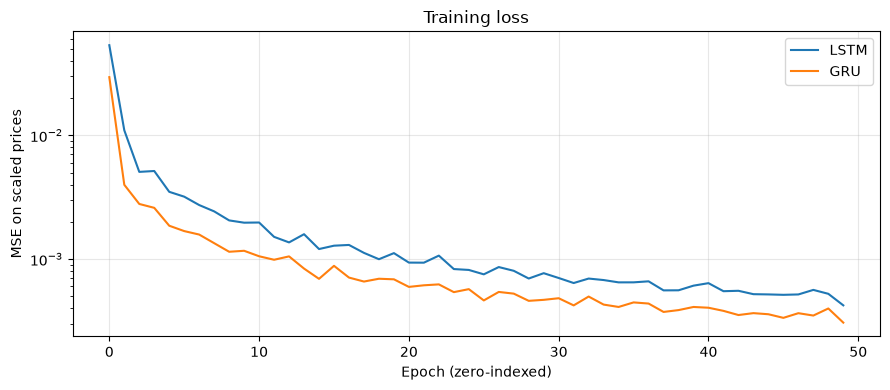

In [ ]:
plt.figure(figsize=(9, 4))

plt.plot(lstm_history, label="LSTM")
plt.plot(gru_history, label="GRU")

plt.title("Training loss")
plt.xlabel("Epoch (zero-indexed)")
plt.ylabel("MSE on scaled prices")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
def predict_prices(model, data_loader, scaler):
    model.eval()
    predictions = []

    with torch.no_grad():
        for X_batch, _ in data_loader:
            X_batch = X_batch.to(device)

            batch_predictions = model(X_batch)
            predictions.append(batch_predictions.cpu().numpy())

    predictions_scaled = np.concatenate(predictions, axis=0)

    return scaler.inverse_transform(predictions_scaled).ravel()


lstm_predictions = predict_prices(lstm_model, test_loader, scaler)
gru_predictions = predict_prices(gru_model, test_loader, scaler)

actual_prices = test_prices.to_numpy()
test_dates = test_prices.index

,Model,Test RMSE
0,Persistence baseline,5.054
1,LSTM,35.802
2,GRU,10.023


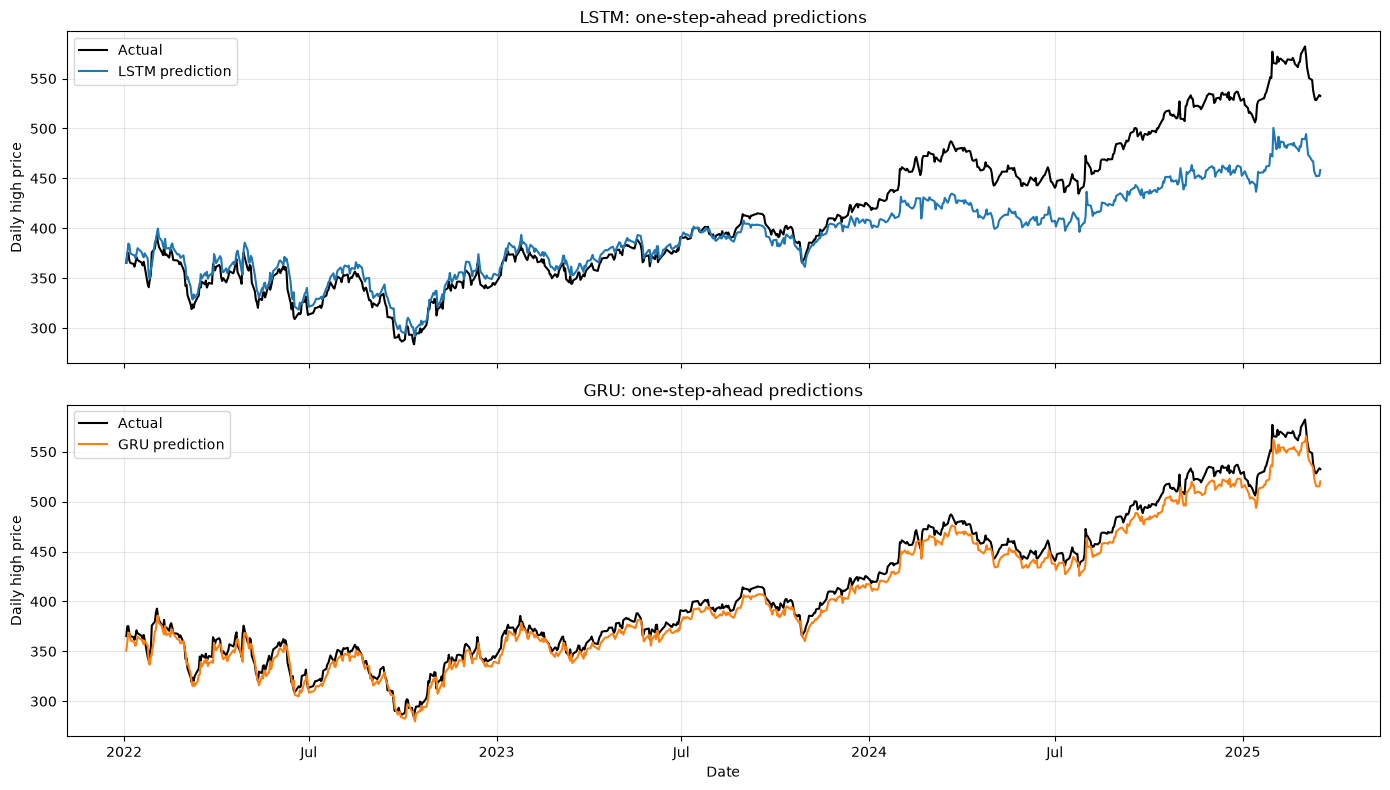

In [ ]:
import matplotlib.dates as mdates

# predicts that the next trading day’s high price will equal the most recent trading day’s high price
baseline_predictions = scaler.inverse_transform(
    X_test[:, -1, :]
).ravel()

results = pd.DataFrame({
    "Model": ["Persistence baseline", "LSTM", "GRU"],
    "Test RMSE": [
        np.sqrt(mean_squared_error(actual_prices, baseline_predictions)),
        np.sqrt(mean_squared_error(actual_prices, lstm_predictions)),
        np.sqrt(mean_squared_error(actual_prices, gru_predictions)),
    ],
})

display(results.round(3))

# Explicitly use datetime values for plotting.
plot_dates = pd.to_datetime(test_dates, utc=True).tz_convert(None)

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True,
    sharey=True,
)

for ax, predictions, name, color in [
    (axes[0], lstm_predictions, "LSTM", "tab:blue"),
    (axes[1], gru_predictions, "GRU", "tab:orange"),
]:
    ax.plot(
        plot_dates,
        actual_prices,
        color="black",
        label="Actual",
        linewidth=1.5,
    )

    ax.plot(
        plot_dates,
        predictions,
        color=color,
        label=f"{name} prediction",
        linewidth=1.5,
    )

    ax.set_title(f"{name}: one-step-ahead predictions")
    ax.set_ylabel("Daily high price")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.minorticks_off()

# The panels share an x-axis, so format it once.
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(locator)
)
axes[-1].set_xlabel("Date")
axes[-1].tick_params(axis="x", labelsize=10)

fig.tight_layout()
plt.show()